In [2]:
import numpy as np
import pandas as pd
import matplotlib as mtp

array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

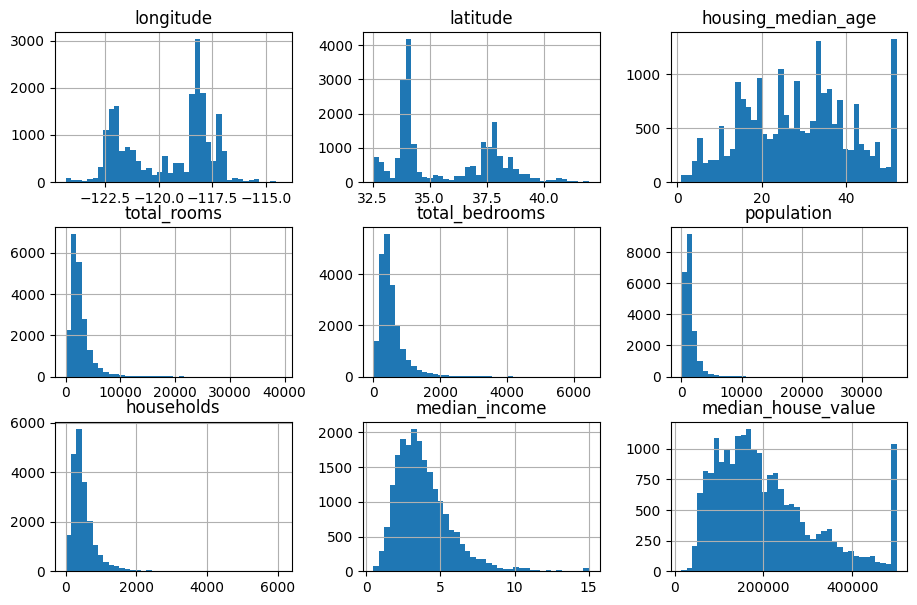

In [3]:
df = pd.read_csv("housing.csv")
df.hist(bins=40 , figsize=(11,7))

shuffle_split --> shuffle_split

In [4]:
def shuffle_split(df , test_ratio):
    random_indices = np.random.permutation(len(df))
    test_size = int(len(df)*test_ratio)
    test_random = random_indices[:test_size]
    train_random = random_indices[test_size:]
    return test_random , train_random
test_set , train_set  = shuffle_split(df , 0.2)
test_set


array([ 2127,  5981,  8163, ..., 12131, 15774,  9205],
      shape=(4128,), dtype=int32)

In [5]:
from zlib import crc32
def is_identifier_in_test_set (identifier , test_ratio):
    return crc32(np.int64(identifier)) < test_ratio *2**32


hash/id

In [6]:
df_with_identifier = df
df_with_identifier["identifier"] = df["longitude"]*1000+df["latitude"]
df_with_identifier["identifier"]

def split_train_test_with_identifier_hash(df,test_ratio ,identifier_column):
    identifiers = df[identifier_column]
    in_test_set = identifiers.apply(lambda id_ : is_identifier_in_test_set(id_ , test_ratio))
    return df.iloc[~in_test_set] , df.iloc[in_test_set]
train_set , test_set = split_train_test_with_identifier_hash(df_with_identifier , 0.2 , "identifier")
train_set

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,identifier
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,-122192.12
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,-122182.14
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,-122202.15
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,-122212.15
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,-122212.15
...,...,...,...,...,...,...,...,...,...,...,...
20635,-121.09,39.48,25.0,1665.0,374.0,845.0,330.0,1.5603,78100.0,INLAND,-121050.52
20636,-121.21,39.49,18.0,697.0,150.0,356.0,114.0,2.5568,77100.0,INLAND,-121170.51
20637,-121.22,39.43,17.0,2254.0,485.0,1007.0,433.0,1.7000,92300.0,INLAND,-121180.57
20638,-121.32,39.43,18.0,1860.0,409.0,741.0,349.0,1.8672,84700.0,INLAND,-121280.57


sampelling bayas


In [7]:
df["median_income_categories"] = pd.cut(df["median_income"],bins=[0.0,1.5,3.0,4.5,6.0,np.inf],
       labels=[1,2,3,4,5])
# df


startifide sampeling


In [8]:
from sklearn.model_selection import StratifiedShuffleSplit
sss = StratifiedShuffleSplit(n_splits=10 , test_size=0.2 , random_state=40)
Stratified_split= []
for train_i , test_i in sss.split(df , df["median_income_categories"]):
    startified_train_set_n = df.iloc[train_i]
    startified_test_set_n = df.iloc[test_i]
    Stratified_split.append([startified_train_set_n,startified_test_set_n])
    startified_train_set_n , startified_test_set_n = Stratified_split[0]
startified_train_set_n["median_income_categories"]

16415    3
1279     3
7741     2
4425     2
1283     2
        ..
1221     2
12640    2
5747     4
16224    3
8967     4
Name: median_income_categories, Length: 16512, dtype: category
Categories (5, int64): [1 < 2 < 3 < 4 < 5]

attribute combination

In [9]:
df["rooms_per_house"] = df["total_rooms"] / df["total_bedrooms"]
df[["rooms_per_house"]]
df["bedrooms_ratio"]= df["total_bedrooms"] / df["total_rooms"]
df["bedrooms_ratio"]

0        0.146591
1        0.155797
2        0.129516
3        0.184458
4        0.172096
           ...   
20635    0.224625
20636    0.215208
20637    0.215173
20638    0.219892
20639    0.221185
Name: bedrooms_ratio, Length: 20640, dtype: float64

prepare_data

In [10]:
train_features = df.drop(["median_house_value"],axis=1)
train_target = df["median_house_value"]
train_target

0        452600.0
1        358500.0
2        352100.0
3        341300.0
4        342200.0
           ...   
20635     78100.0
20636     77100.0
20637     92300.0
20638     84700.0
20639     89400.0
Name: median_house_value, Length: 20640, dtype: float64

data cleaning & mising value

In [11]:
train_features.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   longitude                 20640 non-null  float64 
 1   latitude                  20640 non-null  float64 
 2   housing_median_age        20640 non-null  float64 
 3   total_rooms               20640 non-null  float64 
 4   total_bedrooms            20433 non-null  float64 
 5   population                20640 non-null  float64 
 6   households                20640 non-null  float64 
 7   median_income             20640 non-null  float64 
 8   ocean_proximity           20640 non-null  str     
 9   identifier                20640 non-null  float64 
 10  median_income_categories  20640 non-null  category
 11  rooms_per_house           20433 non-null  float64 
 12  bedrooms_ratio            20433 non-null  float64 
dtypes: category(1), float64(11), str(1)
memory usage: 1.9 MB


In [12]:
train_features_withoutNA = train_features.dropna(subset =["total_bedrooms"])
train_features_withoutNA.info()

<class 'pandas.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype   
---  ------                    --------------  -----   
 0   longitude                 20433 non-null  float64 
 1   latitude                  20433 non-null  float64 
 2   housing_median_age        20433 non-null  float64 
 3   total_rooms               20433 non-null  float64 
 4   total_bedrooms            20433 non-null  float64 
 5   population                20433 non-null  float64 
 6   households                20433 non-null  float64 
 7   median_income             20433 non-null  float64 
 8   ocean_proximity           20433 non-null  str     
 9   identifier                20433 non-null  float64 
 10  median_income_categories  20433 non-null  category
 11  rooms_per_house           20433 non-null  float64 
 12  bedrooms_ratio            20433 non-null  float64 
dtypes: category(1), float64(11), str(1)
memory usage: 2.0 MB


add_data without mising value (with sklearn impute)

In [13]:
from sklearn.impute import SimpleImputer
simpleimputer = SimpleImputer(strategy="median")
train_features_numeric = train_features.select_dtypes(include=[np.number])  #dtypes_change to number
simpleimputer.fit(train_features_numeric)    #fit

simpleimputer.transform(train_features_numeric).shape   #transform

train_features_numeric = pd.DataFrame(simpleimputer.transform(train_features_numeric),columns=train_features_numeric.columns , index = train_features_numeric.index)

categorical features

In [14]:
train_feature_categorical = train_features[["ocean_proximity"]]

#1
from sklearn.preprocessing import OrdinalEncoder
oe = OrdinalEncoder()
ocean_proximity_index = oe.fit_transform(train_feature_categorical)
oe.categories_

#2
from sklearn.preprocessing import OneHotEncoder
ohe = OneHotEncoder()
ocean_proximity_ohe = ohe.fit_transform(train_feature_categorical)
ocean_proximity_ohe.toarray()

array([[0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       [0., 0., 0., 1., 0.],
       ...,
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       [0., 1., 0., 0., 0.]], shape=(20640, 5))

normalization or min_max_scaling


In [16]:
#min_max_scaler
from sklearn.preprocessing import MinMaxScaler
mms = MinMaxScaler(feature_range=(-1,1))
mms.fit_transform(train_features_numeric).max()

#standard_scaler
from sklearn.preprocessing import StandardScaler
ss = StandardScaler()
ss.fit_transform(train_features_numeric)

array([[-1.32783522,  1.05254828,  0.98214266, ..., -1.32802213,
         1.57621018, -1.14993031],
       [-1.32284391,  1.04318455, -0.60701891, ..., -1.32303589,
         1.23044871, -0.99038135],
       [-1.33282653,  1.03850269,  1.85618152, ..., -1.33303335,
         2.34766944, -1.44586501],
       ...,
       [-0.8237132 ,  1.77823747, -0.92485123, ..., -0.82262829,
        -0.28888771,  0.03870567],
       [-0.87362627,  1.77823747, -0.84539315, ..., -0.87259061,
        -0.37444925,  0.12050112],
       [-0.83369581,  1.75014627, -1.00430931, ..., -0.83265073,
        -0.39724386,  0.14290124]], shape=(20640, 11))